In [10]:
import sys, os
sys.path.insert(0, os.getcwd())

import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from train import (load_training_params, setup_training,
                   run_training_loop, evaluate_training, plot_training_log)

In [11]:
# ── What to train ─────────────────────────────────────────────────────────────
train_task = 'wn'

# Frequency grid context: includes all task types the animal may encounter,
# so the network learns to encode across the full frequency range.
task_list  = ['pure', 'harmonic', 'wn']

# ── Training schedule ────────────────────────────────────────────────────────
n_steps         = 15000   # total training batches
k               = 100     # evaluate and save every k batches
seed            = 0
eval_with_noise = True  # if True, evaluation also adds input noise

# ── Load existing checkpoint instead of re-training ──────────────────────────
load_pre_trained = True   # set True to skip training and load from save_dir

# ── Save location ────────────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
save_dir = str(RESULTS_DIR)

In [12]:
state, cfg = setup_training(train_task, task_list, n_steps, k, seed, save_dir)

task_list : ['pure', 'harmonic', 'wn']
train_task: wn
n_freq=50  n_in=54 (freq+fixation+context)  n_rnn=128  alpha=0.100
pulse_dur=50ms  n_pulses=8  stim_dur=400ms  tdim=240 (2400ms)
save_dir  : C:\Users\zhixi\Documents\data\results\tone_generalize\wn\wn_0_lr0.0001_bs64_noise0.1_nrnn128


In [13]:
if load_pre_trained:
    save_path = Path(cfg['save_path'])
    ckpt_files = sorted(save_path.glob('checkpoint_*.pkl'),
                        key=lambda p: int(p.stem.split('_')[-1]))
    if not ckpt_files:
        fallback = save_path / 'checkpoint.pkl'
        if fallback.exists():
            ckpt_files = [fallback]
        else:
            print(f'No checkpoints found in {save_path} — training from scratch.')
            load_pre_trained = False

if load_pre_trained:
    snapshots = []
    for ckpt_path in ckpt_files:
        with open(ckpt_path, 'rb') as f:
            ckpt = pickle.load(f)
        snapshots.append({
            'step':   ckpt['step'],
            'params': jax.tree_util.tree_map(np.array, ckpt['params']),
            'loss':   ckpt.get('loss', float('nan')),
        })
    state = state.replace(params=snapshots[-1]['params'])
    log = None
    print(f'Loaded {len(snapshots)} checkpoints '
          f'(steps {snapshots[0]["step"]}–{snapshots[-1]["step"]})')

if not load_pre_trained:
    log = None
    state, snapshots = run_training_loop(state, train_task, task_list, cfg, snapshot_every=200)

Loaded 30 checkpoints (steps 500–15000)


In [14]:
if log is None:
    log = evaluate_training(state, snapshots, tasks=[train_task], cfg=cfg,
                            eval_with_noise=eval_with_noise)
else:
    print('Evaluation log restored from checkpoint — skipping re-evaluation.')

step    500  wn: hit=0.00 FA=0.00
step   1000  wn: hit=0.00 FA=0.00
step   1500  wn: hit=0.07 FA=0.00
step   2000  wn: hit=0.33 FA=0.00
step   2500  wn: hit=0.25 FA=0.00
step   3000  wn: hit=1.00 FA=0.00
step   3500  wn: hit=0.86 FA=0.00
step   4000  wn: hit=0.97 FA=0.00
step   4500  wn: hit=0.93 FA=0.00
step   5000  wn: hit=0.94 FA=0.00
step   5500  wn: hit=0.97 FA=0.00
step   6000  wn: hit=1.00 FA=0.00
step   6500  wn: hit=1.00 FA=0.00
step   7000  wn: hit=0.99 FA=0.00
step   7500  wn: hit=1.00 FA=0.00
step   8000  wn: hit=0.98 FA=0.00
step   8500  wn: hit=1.00 FA=0.00
step   9000  wn: hit=1.00 FA=0.00
step   9500  wn: hit=1.00 FA=0.00
step  10000  wn: hit=1.00 FA=0.00
step  10500  wn: hit=1.00 FA=0.00
step  11000  wn: hit=1.00 FA=0.00
step  11500  wn: hit=1.00 FA=0.00
step  12000  wn: hit=1.00 FA=0.00
step  12500  wn: hit=1.00 FA=0.00
step  13000  wn: hit=1.00 FA=0.00
step  13500  wn: hit=1.00 FA=0.00
step  14000  wn: hit=1.00 FA=0.00
step  14500  wn: hit=1.00 FA=0.00
step  15000  w

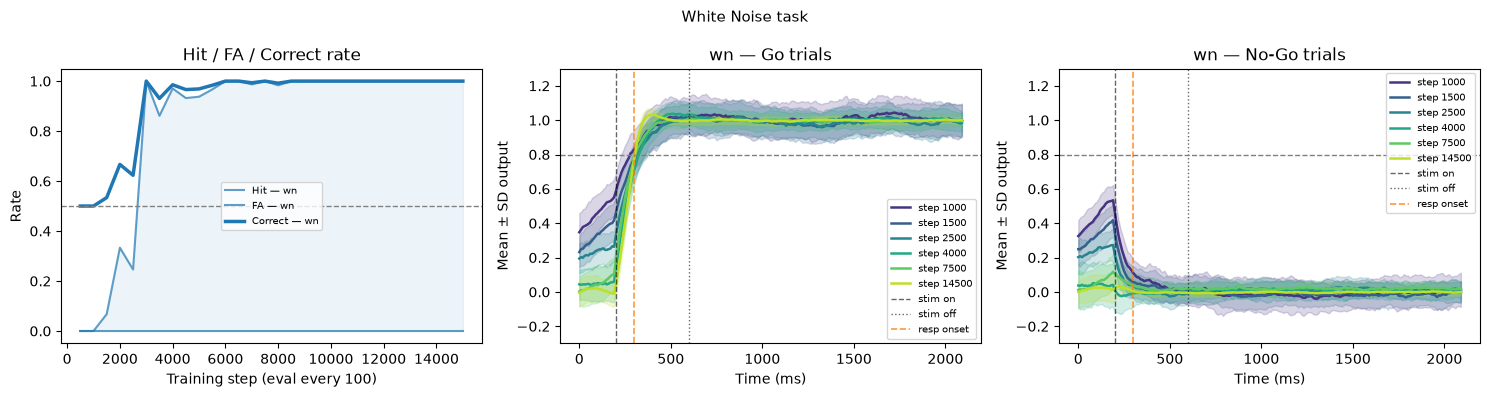

In [15]:
fig = plot_training_log(log, cfg, title='White Noise task', last_snap_step=n_steps)